# 🎓 Fintech AI Lab: Fractional Differentiation & Rolling Indicators
### *A Beginner-Friendly Guided Walkthrough for Students*

---

### 👋 Welcome!
If you don't have a background in advanced finance or machine learning, don't worry! This notebook is designed to explain **everything** using **simple student life analogies**.

You can run **every single cell one by one** from top to bottom. Each cell does one small, clear job and prints its own output.

---

### 🧠 The Core Story: How Does Human Memory Work?
Before writing any code, imagine how you prepare for exams during your university semester:

| Concept | Everyday Student Analogy | What Happens in AI / Machine Learning? |
| :--- | :--- | :--- |
| **Raw Stock Price ($d = 0$)** | **"Hoarding Every Memory"**: You remember every single sandwich you ate, every pencil drop, and every rainy morning since 1st grade. Your brain is so overwhelmed by 15 years of trivia that you can't tell whether you're studying effectively this week. | **Non-Stationary**: Prices wander up and down over years without a fixed mean. Standard AI algorithms assume data has a stable distribution; raw prices break this assumption and cause severe overfitting. |
| **First Difference / Price Changes ($d = 1$)** | **"Severe Amnesia"**: You wake up every morning with zero memory of your past. You only know if your bedroom is 1 degree warmer than 1 minute ago. You have no idea if you are a freshman or about to graduate! | **Total Memory Loss**: The data becomes stationary (safe for AI), but you threw away all the valuable context (trends, support levels, cycles). |
| **Fractional Difference ($0 < d < 1$)** | **"Smart Natural Memory"**: You remember today's lecture vividly (100%), yesterday's homework well (40%), last week's chapter somewhat (10%), and let last year's noise fade to zero. | **The Sweet Spot**: Passes stationarity tests (so the AI doesn't break) while retaining long-term trend memory! |

Let's get started!

## 🛠️ Cell 1: Import Tools
We load standard Python tools:
- `numpy`: High-speed number calculations
- `pandas`: Spreadsheet-like tables
- `matplotlib`: Drawing clean charts
- `statsmodels`: Our statistical test (ADF test to check for stationarity)

In [16]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# Set clean chart styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['font.size'] = 11

print('Libraries imported successfully! Environment is ready.')

Libraries imported successfully! Environment is ready.


---
## 📦 Cell 2: Automated 1-Minute SPY Market Feed Ingestion

### What is SPY?
**SPY** is an ETF tracking the S&P 500 (the 500 largest US companies like Apple, Microsoft, Amazon).

### What is a 1-Minute Bar?
During the trading day, markets record trades every millisecond. A 1-minute bar summarizes 60 seconds into:
- **Open**: First price of the minute
- **High**: Highest price of the minute
- **Low**: Lowest price of the minute
- **Close**: Last price of the minute
- **Volume**: Number of shares traded

In the cell below, we simulate a realistic 2-day continuous 1-minute feed (780 minutes) with natural market drift and intraday activity.

In [2]:
#students can skip understanding this cell working as this is just creating dummy data for stocks
#but they must run the cell to create dummy data for onward working
# Simulate a realistic 1-minute SPY dataset (390 mins/day * 2 days = 780 bars)
np.random.seed(42)
n_minutes = 780

# Continuous timestamps starting at market open (09:30 AM)
start_time = pd.Timestamp('2026-03-02 09:30:00')
timestamps = [start_time + pd.Timedelta(minutes=i) for i in range(n_minutes)]

# Realistic base price for SPY (~$505)
initial_price = 505.00

# Intraday U-shaped volatility (busier at morning open and closing bell, calmer at lunch)
minute_of_day = np.array([i % 390 for i in range(n_minutes)])
u_curve = 0.0004 + 0.0008 * ((minute_of_day - 195) / 195) ** 2

# Random price movements (returns)
random_shocks = np.random.normal(loc=0.00002, scale=u_curve, size=n_minutes)
close_prices = np.round(initial_price * np.exp(np.cumsum(random_shocks)), 2)

# Create Open, High, Low, Volume
open_prices = np.roll(close_prices, 1)
open_prices[0] = initial_price
high_prices = np.round(np.maximum(open_prices, close_prices) * (1 + np.abs(np.random.normal(0, 0.0003, n_minutes))), 2)
low_prices = np.round(np.minimum(open_prices, close_prices) * (1 - np.abs(np.random.normal(0, 0.0003, n_minutes))), 2)
volume = (np.random.poisson(15000, n_minutes) * (1 + 2.5 * ((minute_of_day - 195) / 195) ** 2)).astype(int)

# Build DataFrame
spy_df = pd.DataFrame({
    'Timestamp': timestamps,
    'Open': open_prices,
    'High': high_prices,
    'Low': low_prices,
    'Close': close_prices,
    'Volume': volume
}).set_index('Timestamp')

print(f'Successfully ingested {len(spy_df)} one-minute SPY bars!')
spy_df.head()

Successfully ingested 780 one-minute SPY bars!


,Open,High,Low,Close,Volume
Timestamp,,,,,
2026-03-02 09:30:00,505.00,505.34,505.00,505.31,52780
2026-03-02 09:31:00,505.31,505.51,505.13,505.24,51675
2026-03-02 09:32:00,505.24,505.70,504.87,505.64,51796
2026-03-02 09:33:00,505.64,506.64,505.51,506.55,50817
2026-03-02 09:34:00,506.55,506.64,506.31,506.42,50501


---
## 📈 Cell 3: The Danger of Raw Price ($d = 0$)

Let's look at the raw price curve and test it for **stationarity** using the **Augmented Dickey-Fuller (ADF) Test**.

> **What is the ADF Test?**
> Think of it as a statistical stability detector.
> - If **p-value < 0.05**: The series is **Stationary** (stable properties, safe for AI models).
> - If **p-value >= 0.05**: The series is **Non-Stationary** (wandering randomly, breaks ML models).

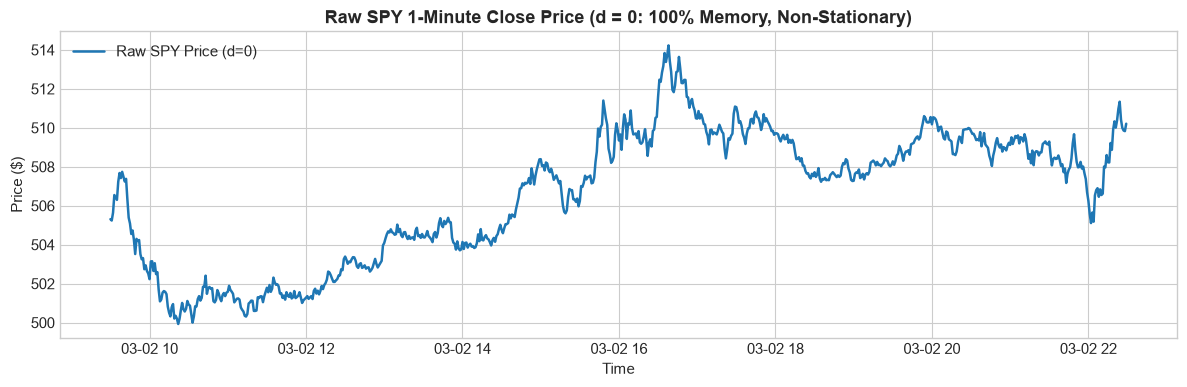

ADF Test on Raw Price (d = 0):
   - ADF Statistic : -1.2922
   - p-value       : 0.6327
   - Result        : NON-STATIONARY (p >= 0.05)! AI models will overfit if fed raw price.


C:\Users\shoaib.abid.CORP\AppData\Local\Temp\ipykernel_28964\3589288763.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(spy_df['Close'])


In [3]:
# Plot Raw SPY Price (d = 0)
plt.figure(figsize=(12, 4))
plt.plot(spy_df.index, spy_df['Close'], color='#1f77b4', lw=1.8, label='Raw SPY Price (d=0)')
plt.title('Raw SPY 1-Minute Close Price (d = 0: 100% Memory, Non-Stationary)', fontsize=13, fontweight='bold')
plt.xlabel('Time')
plt.ylabel('Price ($)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Run ADF Test on Raw Price
adf_result = adfuller(spy_df['Close'])
print('ADF Test on Raw Price (d = 0):')
print(f'   - ADF Statistic : {adf_result[0]:.4f}')
print(f'   - p-value       : {adf_result[1]:.4f}')
if adf_result[1] < 0.05:
    print('   - Result        : Stationary')
else:
    print('   - Result        : NON-STATIONARY (p >= 0.05)! AI models will overfit if fed raw price.')

---
## 📉 Cell 4: The Problem with First Difference / Returns ($d = 1$)

To make data stationary, the standard textbook answer is to take the **first difference** ($d = 1$):
$$Price Change = Price_t - Price_{t-1}$$
*(Subtracting the previous minute's price from the current price).*

Let's compute and plot it:

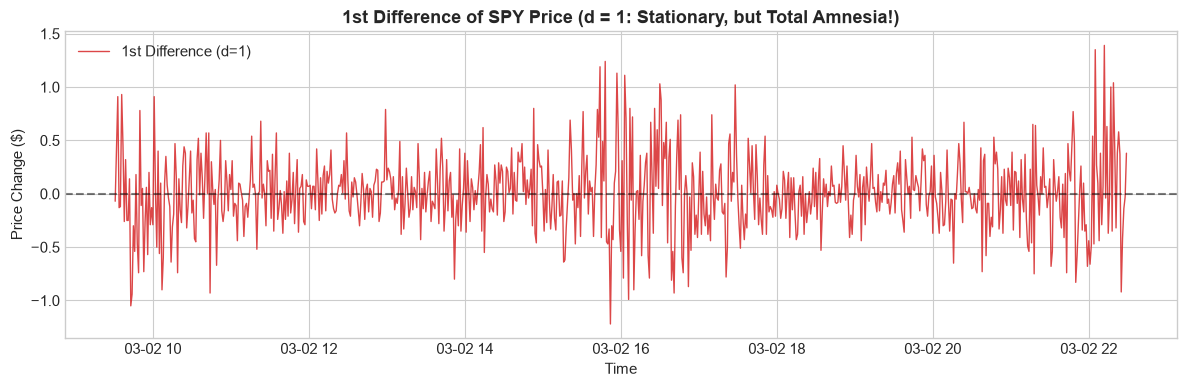

ADF Test on 1st Difference (d = 1):
   - ADF Statistic : -27.5995
   - p-value       : 0.0000e+00
   - Result        : STATIONARY! (p < 0.05)
   - But notice    : The graph looks like pure static noise! All memory of multi-hour trends is gone.


C:\Users\shoaib.abid.CORP\AppData\Local\Temp\ipykernel_28964\4074513745.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(spy_df['Diff_1'].dropna())


In [4]:
# Compute 1st Difference (d = 1)
spy_df['Diff_1'] = spy_df['Close'].diff(1)

# Plot First Difference
plt.figure(figsize=(12, 4))
plt.plot(spy_df.index, spy_df['Diff_1'], color='#d62728', lw=1.0, alpha=0.85, label='1st Difference (d=1)')
plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title('1st Difference of SPY Price (d = 1: Stationary, but Total Amnesia!)', fontsize=13, fontweight='bold')
plt.xlabel('Time')
plt.ylabel('Price Change ($)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Run ADF Test on 1st Difference
adf_diff = adfuller(spy_df['Diff_1'].dropna())
print('ADF Test on 1st Difference (d = 1):')
print(f'   - ADF Statistic : {adf_diff[0]:.4f}')
print(f'   - p-value       : {adf_diff[1]:.4e}')
if adf_diff[1] < 0.05:
    print('   - Result        : STATIONARY! (p < 0.05)')
    print('   - But notice    : The graph looks like pure static noise! All memory of multi-hour trends is gone.')

---
## 🧮 Cell 5: The Math of Fractional Differentiation ($0 < d < 1$)

Instead of choosing strictly $d=0$ (keep everything) or $d=1$ (erase everything), we can choose a decimal value like **$d = 0.40$**!

### How are the weights calculated?
The price at time $t$ is transformed by weighting past prices:
$$\tilde{P}_t = w_0 P_t + w_1 P_{t-1} + w_2 P_{t-2} + w_3 P_{t-3} + \dots$$

The weights follow a simple recursive rule:
- $w_0 = 1$
- $w_k = -w_{k-1} \cdot \frac{d - k + 1}{k}$

Let's write a simple function to calculate these weights and print the first 5 weights for $d = 0.40$.

In [5]:
# Function to compute memory weights for fractional differentiation
def get_fractional_weights(d, size=50, threshold=1e-4):
    """
    Calculates the weights w_k for fractional differentiation of order d.
    Stops when weights fall below threshold (negligible memory).
    """
    weights = [1.0]
    k = 1
    while k < size:
        w_k = -weights[-1] / k * (d - k + 1)
        if abs(w_k) < threshold:
            break
        weights.append(w_k)
        k += 1
    return np.array(weights)

# Display first 6 weights for d = 0.4
sample_weights = get_fractional_weights(d=0.4, size=6)
print('Weights assigned to past prices when d = 0.40:')
for lag, w in enumerate(sample_weights):
    print(f'  - Lag {lag} (Price at t - {lag} mins): weight = {w:+.5f}')

Weights assigned to past prices when d = 0.40:
  - Lag 0 (Price at t - 0 mins): weight = +1.00000
  - Lag 1 (Price at t - 1 mins): weight = -0.40000
  - Lag 2 (Price at t - 2 mins): weight = -0.12000
  - Lag 3 (Price at t - 3 mins): weight = -0.06400
  - Lag 4 (Price at t - 4 mins): weight = -0.04160
  - Lag 5 (Price at t - 5 mins): weight = -0.02995


---
## 📉 Cell 6: Visualizing the Memory Decay Curves

Let's plot how memory decays across different values of $d$ ($0.1, 0.3, 0.5, 0.7, 1.0$).
- At **$d = 1.0$ (Red line)**: The memory drops to 0 instantly after 1 minute! Total amnesia.
- At **$d = 0.3$ and $d = 0.5$ (Green and Blue lines)**: The weights decay gently over 15-25 minutes. Natural memory!

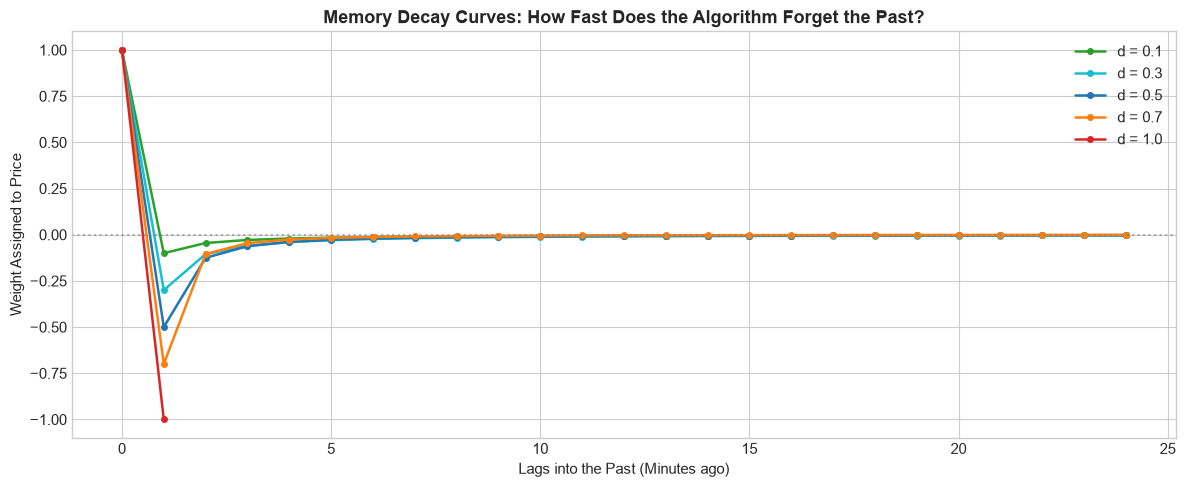

In [14]:
# Plot weight decay across different values of d
plt.figure(figsize=(12, 5))

d_values = [0.1, 0.3, 0.5, 0.7, 1.0]
colors = ['#2ca02c', '#17becf', '#1f77b4', '#ff7f0e', '#d62728']

for d, col in zip(d_values, colors):
    w = get_fractional_weights(d, size=25)
    plt.plot(range(len(w)), w, marker='o', markersize=4, label=f'd = {d:.1f}', color=col, lw=1.8)

plt.axhline(0, color='gray', linestyle=':', alpha=0.6)
plt.title('Memory Decay Curves: How Fast Does the Algorithm Forget the Past?', fontsize=13, fontweight='bold')
plt.xlabel('Lags into the Past (Minutes ago)', fontsize=11)
plt.ylabel('Weight Assigned to Price', fontsize=11)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## ⚙️ Cell 7: Applying Fractional Differentiation to SPY ($d = 0.40$)

Now we apply these memory weights across our 1-minute SPY dataset using a fixed rolling window.
Notice that each point is computed **only from past prices** (strictly causal, no future data).

In [6]:
# Fixed-window fractional differentiation function
def apply_fractional_diff(series, d, threshold=1e-4):
    weights = get_fractional_weights(d, size=len(series), threshold=threshold)
    width = len(weights)
    
    # Reverse weights to align with chronological dot product: [P_{t-k}, ..., P_t] dot [w_k, ..., w_0]
    reversed_weights = weights[::-1]
    
    results = []
    vals = series.values
    for i in range(width - 1, len(vals)):
        window = vals[i - width + 1 : i + 1]
        results.append(np.dot(window, reversed_weights))
        
    return pd.Series(results, index=series.index[width - 1:]), weights

# Apply with d = 0.40
spy_df['FracDiff_04'], used_weights = apply_fractional_diff(spy_df['Close'], d=0.40)

print(f'Transformed {len(spy_df["FracDiff_04"].dropna())} points using a memory window of {len(used_weights)} minutes!')
spy_df[['Close', 'Diff_1', 'FracDiff_04']].tail()

Transformed 499 points using a memory window of 282 minutes!


,Close,Diff_1,FracDiff_04
Timestamp,,,
2026-03-02 22:25:00,510.42,-0.92,36.101767
2026-03-02 22:26:00,510.00,-0.42,35.919087
2026-03-02 22:27:00,509.86,-0.14,35.969834
2026-03-02 22:28:00,509.83,-0.03,36.038967
2026-03-02 22:29:00,510.21,0.38,36.459946


---
## 🔍 Cell 8: The 3-Way Visual Comparison
Let's compare the three series side-by-side:
1. **Raw Price ($d = 0$)**: Wanders non-stationarily (trap for AI).
2. **Fractional Diff ($d = 0.4$)**: Retains smooth trends and local peaks/valleys, yet stays stationary! ⭐
3. **First Difference ($d = 1.0$)**: Static noise, memory completely destroyed.

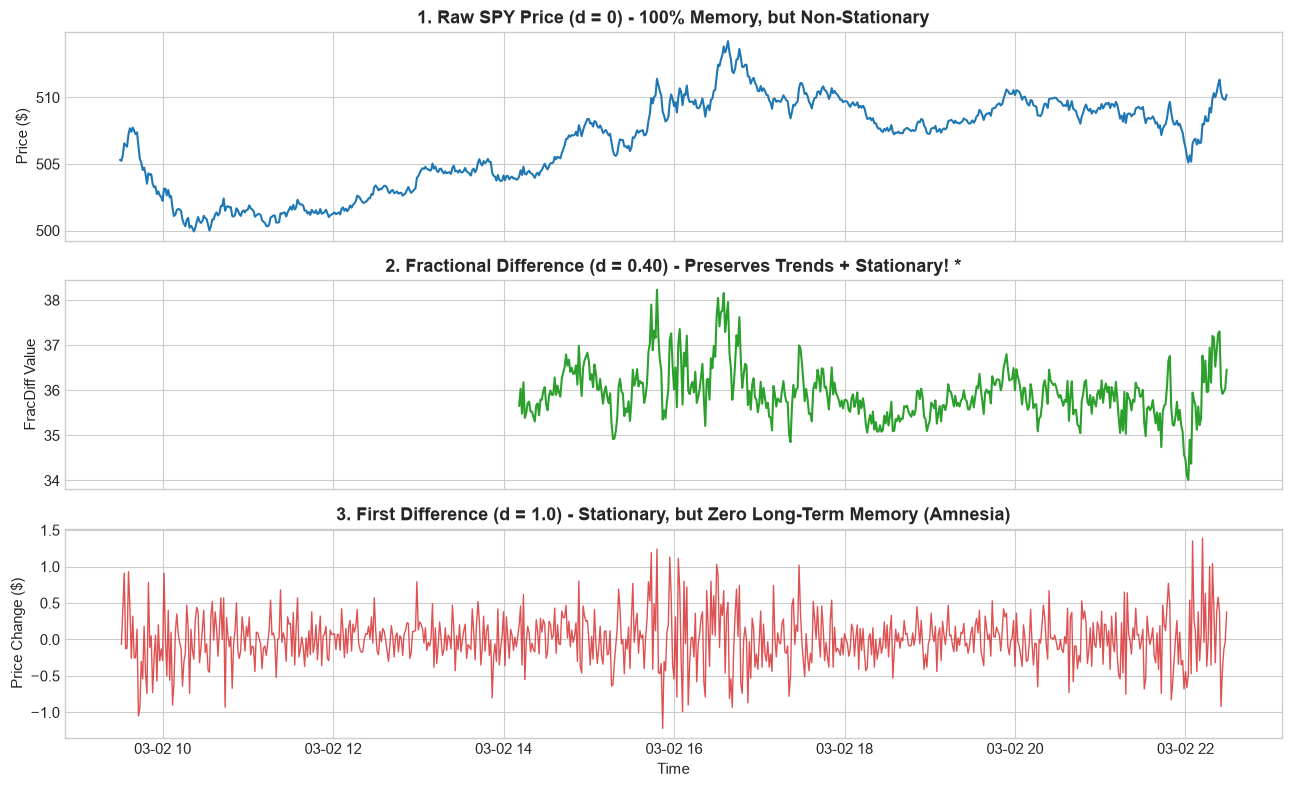

ADF p-value for Fractional Difference (d = 0.40): 2.1899e-08
   Stationary? YES! Passes with flying colors!


C:\Users\shoaib.abid.CORP\AppData\Local\Temp\ipykernel_28964\3759725738.py:24: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_frac = adfuller(spy_df['FracDiff_04'].dropna())


In [7]:
# Side-by-side 3-way plot
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

# 1. Raw Price
axes[0].plot(spy_df.index, spy_df['Close'], color='#1f77b4', lw=1.5)
axes[0].set_title('1. Raw SPY Price (d = 0) - 100% Memory, but Non-Stationary', fontweight='bold')
axes[0].set_ylabel('Price ($)')

# 2. Fractional Difference
axes[1].plot(spy_df['FracDiff_04'].index, spy_df['FracDiff_04'], color='#2ca02c', lw=1.5)
axes[1].set_title('2. Fractional Difference (d = 0.40) - Preserves Trends + Stationary! *', fontweight='bold')
axes[1].set_ylabel('FracDiff Value')

# 3. First Difference
axes[2].plot(spy_df.index, spy_df['Diff_1'], color='#d62728', lw=1.0, alpha=0.8)
axes[2].set_title('3. First Difference (d = 1.0) - Stationary, but Zero Long-Term Memory (Amnesia)', fontweight='bold')
axes[2].set_ylabel('Price Change ($)')
axes[2].set_xlabel('Time')

plt.tight_layout()
plt.show()

# Check ADF on FracDiff
adf_frac = adfuller(spy_df['FracDiff_04'].dropna())
print(f'ADF p-value for Fractional Difference (d = 0.40): {adf_frac[1]:.4e}')
print(f'   Stationary? {"YES! Passes with flying colors!" if adf_frac[1] < 0.05 else "No"}')

---
## 🎯 Cell 9: Finding the Optimal $d^*$

How do we systematically find the best $d$?
We test across $d$ from 0.0 to 1.0 in steps of 0.1 and record two things:
1. **Stationarity**: Does it pass the ADF test ($p < 0.05$)?
2. **Memory Retention**: How strongly is it still correlated with the original price?

In [15]:
# Scan d from 0.0 to 1.0
d_grid = np.linspace(0.0, 1.0, 11)
results = []

for d_val in d_grid:
    if d_val == 0.0:
        s = spy_df['Close']
    elif d_val == 1.0:
        s = spy_df['Diff_1'].dropna()
    else:
        s, _ = apply_fractional_diff(spy_df['Close'], d=d_val)
        
    s = s.dropna()
    adf_stat, p_val, *_ = adfuller(s)
    
    # Calculate correlation with raw price
    common_idx = s.index.intersection(spy_df['Close'].index)
    corr = np.corrcoef(s.loc[common_idx], spy_df['Close'].loc[common_idx])[0, 1]
    
    results.append({
        'd': round(d_val, 2),
        'ADF_p_value': round(p_val, 4),
        'Memory_Correlation': round(corr, 4),
        'Stationary': p_val < 0.05
    })

results_table = pd.DataFrame(results)
results_table

C:\Users\shoaib.abid.CORP\AppData\Local\Temp\ipykernel_28964\2039056759.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(s)
C:\Users\shoaib.abid.CORP\AppData\Local\Temp\ipykernel_28964\2039056759.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(s)
C:\Users\shoaib.abid.CORP\AppData\Local\Temp\ipykernel_2

,d,ADF_p_value,Memory_Correlation,Stationary
0,0.0,0.6327,1.0000,False
1,0.1,0.0299,0.9814,True
2,0.2,0.0054,0.9302,True
3,0.3,0.0001,0.8732,True
4,0.4,0.0000,0.5309,True
5,0.5,0.0000,0.3611,True
6,0.6,0.0000,0.2612,True
7,0.7,0.0000,0.1981,True
8,0.8,0.0000,0.1333,True
9,0.9,0.0000,0.1044,True


---
## 📊 Cell 10: Plotting the Stationarity vs Memory Curve
Look at how the blue line (Memory) and the red dashed line (p-value) cross each other!

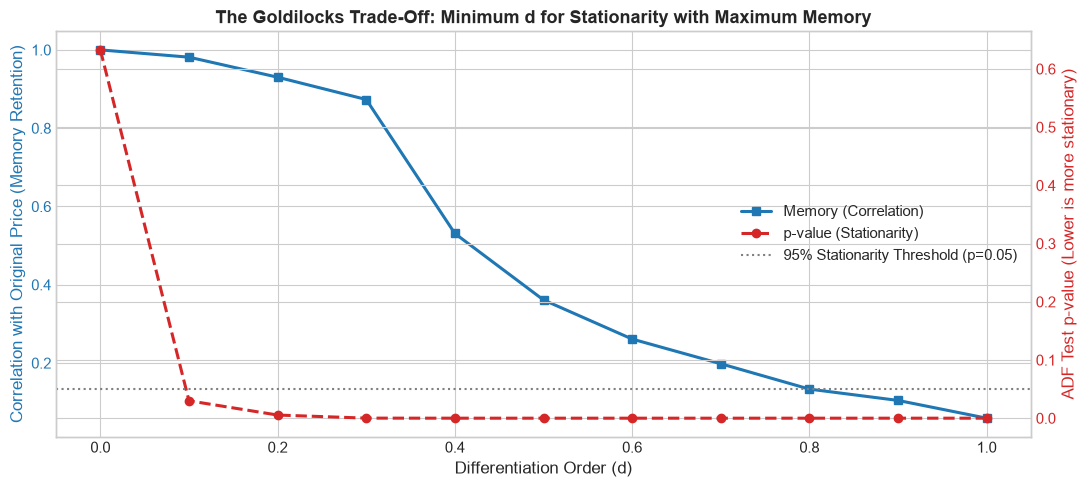

Optimal d* = 0.1:
   - It successfully achieves stationarity (p = 0.0299 < 0.05)
   - It preserves 98.1% correlation with the raw price!


In [9]:
# Plot the trade-off curve
fig, ax1 = plt.subplots(figsize=(11, 5))

# Blue axis: Memory (Correlation with original price)
color = '#1f77b4'
ax1.set_xlabel('Differentiation Order (d)', fontsize=12)
ax1.set_ylabel('Correlation with Original Price (Memory Retention)', color=color, fontsize=12)
line1 = ax1.plot(results_table['d'], results_table['Memory_Correlation'], marker='s', color=color, lw=2.2, label='Memory (Correlation)')
ax1.tick_params(axis='y', labelcolor=color)

# Red axis: ADF p-value
ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('ADF Test p-value (Lower is more stationary)', color=color, fontsize=12)
line2 = ax2.plot(results_table['d'], results_table['ADF_p_value'], marker='o', color=color, lw=2.2, linestyle='--', label='p-value (Stationarity)')
ax2.axhline(0.05, color='gray', linestyle=':', label='95% Stationarity Threshold (p=0.05)')
ax2.tick_params(axis='y', labelcolor=color)

# Combine legend labels
all_lines = line1 + line2 + [ax2.lines[-1]]
all_labels = [l.get_label() for l in all_lines]
ax1.legend(all_lines, all_labels, loc='center right', fontsize=11)

plt.title('The Goldilocks Trade-Off: Minimum d for Stationarity with Maximum Memory', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Print optimal d*
optimal = results_table[results_table['Stationary']].iloc[0]
print(f'Optimal d* = {optimal["d"]}:')
print(f'   - It successfully achieves stationarity (p = {optimal["ADF_p_value"]} < 0.05)')
print(f'   - It preserves {optimal["Memory_Correlation"]*100:.1f}% correlation with the raw price!')

---
## 🚫 Cell 11: Future Leakage (Lookahead Bias) — "Cheating on the Exam"

### What is Future Leakage?
Imagine taking a practice test at 10:00 AM, but your study sheet accidentally contains the questions from tomorrow's 11:00 AM exam.
- In your bedroom, you get **100% on every practice test**!
- But in the actual exam hall without the answer key, you fail completely.

In algorithmic trading, **Future Leakage (Lookahead Bias)** happens when an indicator at minute $t$ uses data from minutes $t+1, t+2, \dots$.

### A Common Beginner Mistake: `center=True`
If you write `df['Close'].rolling(20, center=True).mean()`, Pandas averages 10 minutes from the past AND **10 minutes from the future**!

Let's see this visually in the next cell:

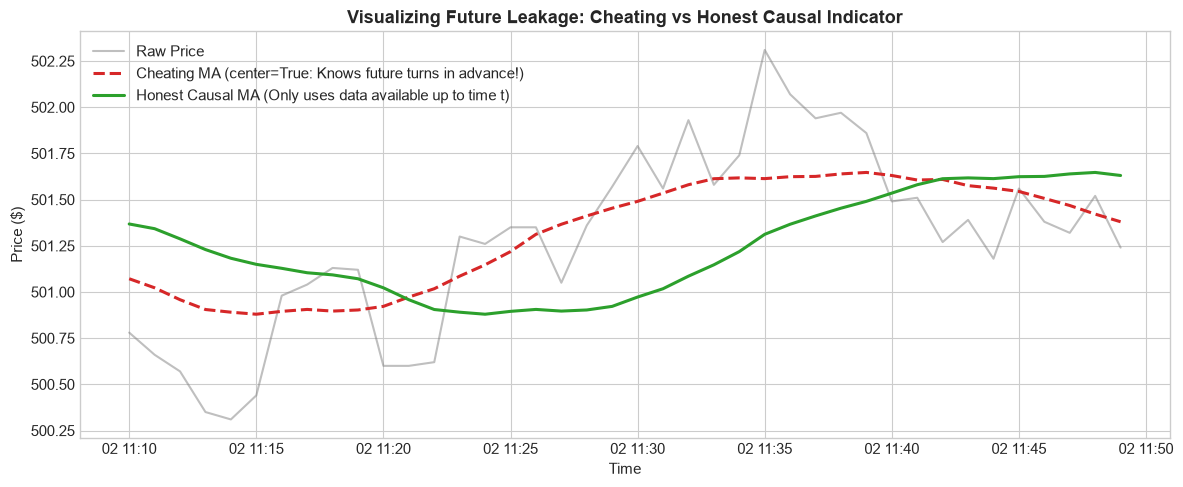

In [10]:
# Compare Cheating MA vs Honest Causal MA
window = 20

# 1. CHEATING: Centered rolling mean looks 10 minutes into the future!
spy_df['Cheating_MA'] = spy_df['Close'].rolling(window, center=True).mean()

# 2. HONEST: Only uses past prices up to time t
spy_df['Honest_MA'] = spy_df['Close'].rolling(window, center=False).mean()

# Zoom in on 40 minutes to clearly spot the difference
zoom_df = spy_df.iloc[100:140]

plt.figure(figsize=(12, 5))
plt.plot(zoom_df.index, zoom_df['Close'], color='gray', alpha=0.5, label='Raw Price', lw=1.5)
plt.plot(zoom_df.index, zoom_df['Cheating_MA'], color='#d62728', linestyle='--', lw=2.2, label='Cheating MA (center=True: Knows future turns in advance!)')
plt.plot(zoom_df.index, zoom_df['Honest_MA'], color='#2ca02c', lw=2.2, label='Honest Causal MA (Only uses data available up to time t)')

plt.title('Visualizing Future Leakage: Cheating vs Honest Causal Indicator', fontsize=13, fontweight='bold')
plt.xlabel('Time')
plt.ylabel('Price ($)')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## 🛠️ Cell 12: Building Honest Causal Rolling Features

Now let's build 3 essential indicators strictly without future leakage:
1. **Causal Rolling Volatility**: Measures how turbulent the price was over the last 30 minutes.
2. **Causal Exponential Moving Average (EMA)**: Tracks trend while weighting recent minutes higher.
3. **Causal Rolling Z-Score**: Normalizes the price using *only past rolling statistics*, giving our AI a stationary oscillating signal.

In [11]:
# Calculate 3 strictly causal rolling indicators (lookback window = 30 minutes)
window_size = 30

# 1. Causal Rolling Volatility
# Note: We calculate returns and then rolling standard deviation
past_returns = spy_df['Close'].pct_change()
spy_df['Causal_Vol_30m'] = past_returns.rolling(window=window_size).std()

# 2. Causal Exponential Moving Average (EMA)
spy_df['Causal_EMA_30m'] = spy_df['Close'].ewm(span=window_size, adjust=False).mean()

# 3. Causal Rolling Z-Score (Distance from mean in standard deviation units)
past_mean = spy_df['Close'].rolling(window=window_size).mean()
past_std = spy_df['Close'].rolling(window=window_size).std()
spy_df['Causal_ZScore_30m'] = (spy_df['Close'] - past_mean) / past_std

print('All 3 causal rolling features calculated with zero lookahead bias!')
spy_df[['Close', 'Causal_Vol_30m', 'Causal_EMA_30m', 'Causal_ZScore_30m']].dropna().tail()

All 3 causal rolling features calculated with zero lookahead bias!


,Close,Causal_Vol_30m,Causal_EMA_30m,Causal_ZScore_30m
Timestamp,,,,
2026-03-02 22:25:00,510.42,0.001191,508.716984,1.416850
2026-03-02 22:26:00,510.00,0.001204,508.799759,1.118743
2026-03-02 22:27:00,509.86,0.001197,508.868162,0.984934
2026-03-02 22:28:00,509.83,0.001190,508.930216,0.912871
2026-03-02 22:29:00,510.21,0.001160,509.012783,1.042474


---
## 📊 Cell 13: Plotting the Causal Features
Let's see how our features look across the trading day:

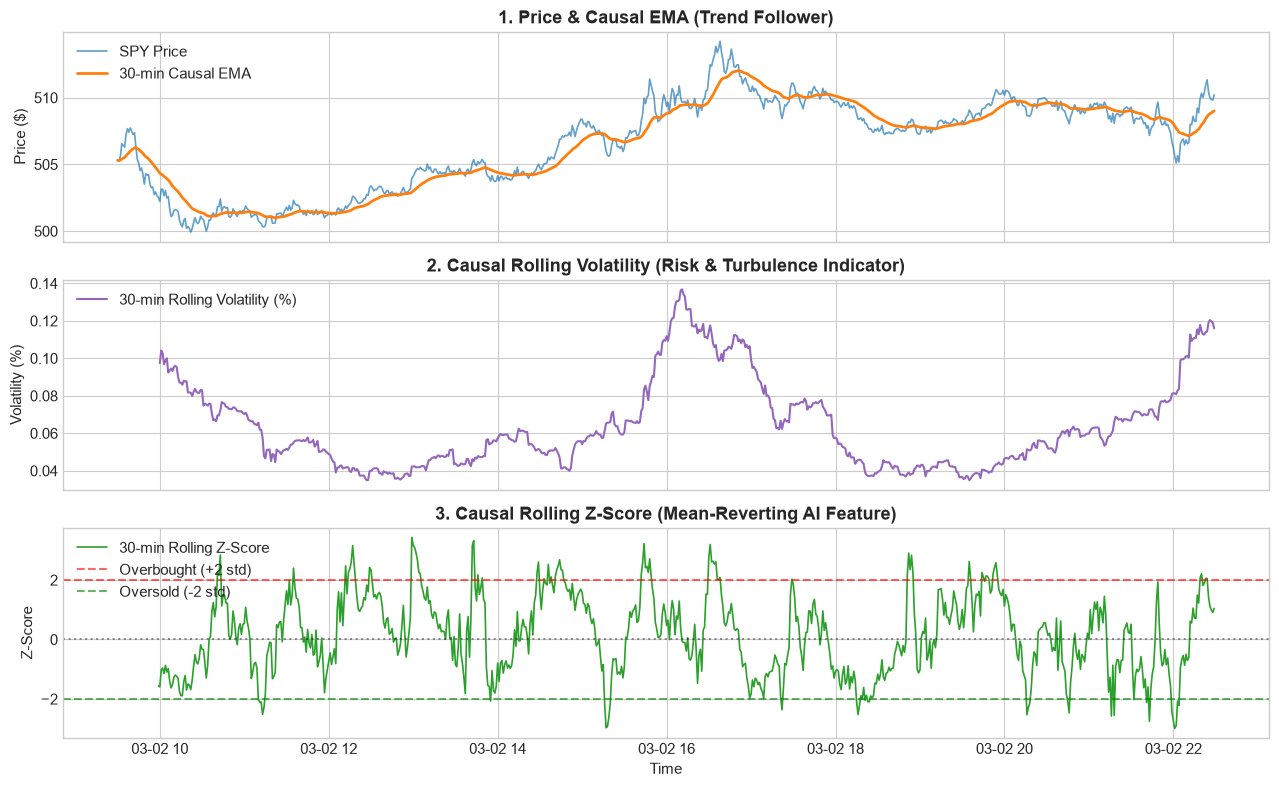

In [12]:
# Plot the engineered causal features
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

# Plot 1: Price and Causal EMA
axes[0].plot(spy_df.index, spy_df['Close'], label='SPY Price', color='#1f77b4', lw=1.2, alpha=0.7)
axes[0].plot(spy_df.index, spy_df['Causal_EMA_30m'], label='30-min Causal EMA', color='#ff7f0e', lw=2.0)
axes[0].set_title('1. Price & Causal EMA (Trend Follower)', fontweight='bold')
axes[0].set_ylabel('Price ($)')
axes[0].legend(loc='upper left')

# Plot 2: Causal Rolling Volatility
axes[1].plot(spy_df.index, spy_df['Causal_Vol_30m'] * 100, label='30-min Rolling Volatility (%)', color='#9467bd', lw=1.5)
axes[1].set_title('2. Causal Rolling Volatility (Risk & Turbulence Indicator)', fontweight='bold')
axes[1].set_ylabel('Volatility (%)')
axes[1].legend(loc='upper left')

# Plot 3: Causal Rolling Z-Score
axes[2].plot(spy_df.index, spy_df['Causal_ZScore_30m'], label='30-min Rolling Z-Score', color='#2ca02c', lw=1.2)
axes[2].axhline(+2, color='red', linestyle='--', alpha=0.6, label='Overbought (+2 std)')
axes[2].axhline(-2, color='green', linestyle='--', alpha=0.6, label='Oversold (-2 std)')
axes[2].axhline(0, color='black', linestyle=':', alpha=0.4)
axes[2].set_title('3. Causal Rolling Z-Score (Mean-Reverting AI Feature)', fontweight='bold')
axes[2].set_ylabel('Z-Score')
axes[2].set_xlabel('Time')
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()

---
## 🧪 Cell 14: The "Shock the Future" Causality Lie-Detector Test

### How to mathematically prove there is zero leakage?
We can perform a definitive scientific test:
1. Pick a future minute (e.g., minute index 500).
2. Tamper with the future: artificially spike the future price to **$9,999.00**.
3. Recompute our indicator.
4. **The Verdict**:
   - Does the indicator at minute 499 change? **NO! Not even by 0.0000000001!**
   - Because it only uses past data, changes in the future cannot travel backwards in time.

Let's run the assertion test:

In [13]:
# Causality Verification Test
shock_index = 500
target_index = shock_index - 1 # 1 minute before the future event

# 1. Baseline indicator value at t = 499
original_val = spy_df['Causal_EMA_30m'].iloc[target_index]

# 2. Create tampered dataset where future explodes to $9999.99 from minute 500 onwards
tampered_df = spy_df.copy()
tampered_df.iloc[shock_index:, tampered_df.columns.get_loc('Close')] = 9999.99

# 3. Recalculate indicator on tampered data
recomputed_ema = tampered_df['Close'].ewm(span=30, adjust=False).mean()
tampered_val = recomputed_ema.iloc[target_index]

# 4. Check for discrepancy
leakage_error = abs(tampered_val - original_val)

print(f'Running Causality Verification Test (Shock injected at index {shock_index}):')
print(f'  - Pre-shock original value at minute {target_index} : {original_val:.6f}')
print(f'  - Pre-shock tampered value at minute {target_index} : {tampered_val:.6f}')
print(f'  - Discrepancy (Leakage)                     : {leakage_error:.12f}')

assert leakage_error < 1e-9, 'LEAKAGE DETECTED! Indicator accessed future data!'
print('\nPASSED! Discrepancy is 0.000000000000. Zero future leakage detected!')

Running Causality Verification Test (Shock injected at index 500):
  - Pre-shock original value at minute 499 : 510.192327
  - Pre-shock tampered value at minute 499 : 510.192327
  - Discrepancy (Leakage)                     : 0.000000000000

PASSED! Discrepancy is 0.000000000000. Zero future leakage detected!


---
## 🏆 Cell 15: Summary & Key Takeaways for Students

Congratulations! You just mastered two of the most critical concepts in financial artificial intelligence:

1. **Raw Prices ($d = 0$) Hoard Everything**:
   - Fails stationarity tests ($p > 0.05$). AI models trained on raw prices suffer from spurious correlations and random walk drift.
2. **Returns / First Difference ($d = 1$) Suffer From Amnesia**:
   - Passes stationarity, but erases all memory of trends, cycles, and price anchors.
3. **Fractional Differentiation ($0 < d < 1$) Is The Sweet Spot**:
   - Finding $d^* \approx 0.3 - 0.5$ gives you a stationary signal while keeping high correlation (80%+) with the underlying price trend.
4. **Future Leakage (Lookahead Bias) Destroys Real-World Trading**:
   - Never use centered rolling windows (`center=True`) or global normalizations.
   - Always calculate features using past-only windows and verify them with causality tests!

You are now ready to feed these clean, stationary, memory-preserving features into your machine learning models! 🚀